# Starter notebook
---

## Example: Quadratic-band wall penalty with visualization

### Quadratic Band (Soft Wall)

$$
\phi(d) =
\begin{cases}
\frac{1}{2}(R - d)^2, & d \le R, \\
0, & d > R.
\end{cases}
$$
#### Behavior:
  - Smooth gradients
  - Creates a "buffer zone" around walls


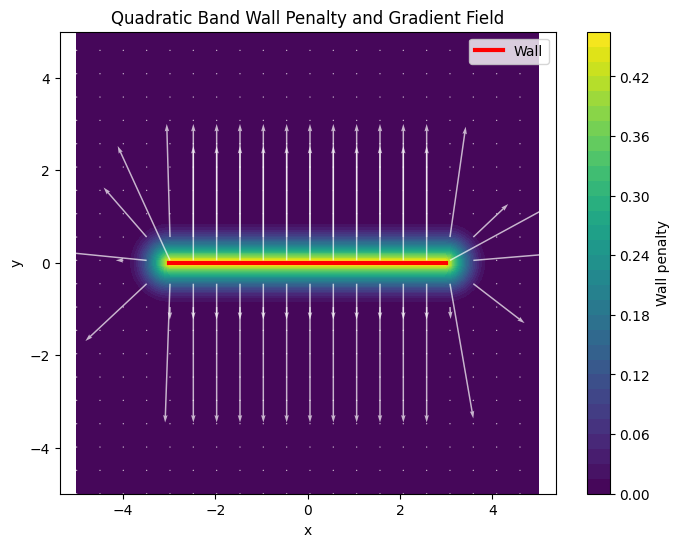

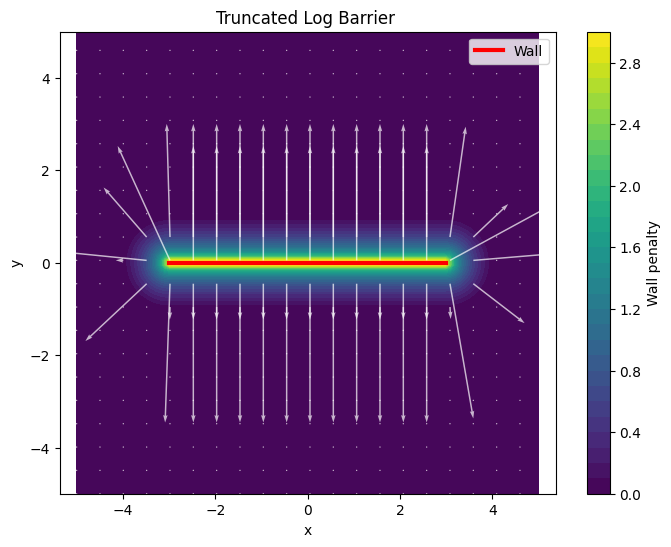

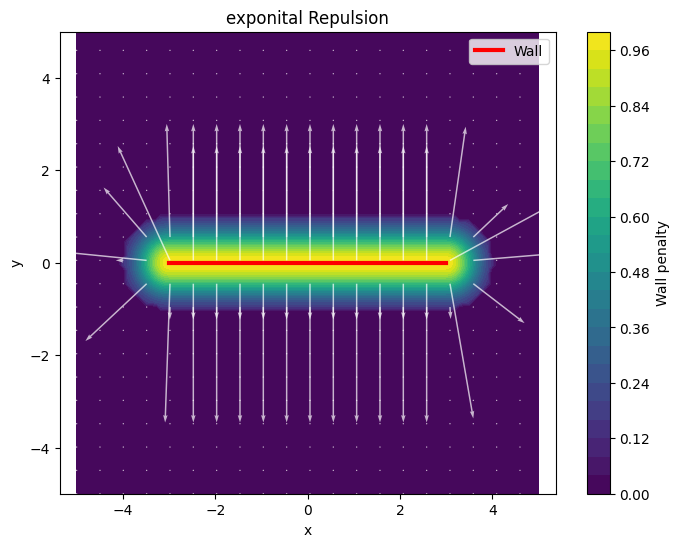

In [1]:
# Example: Quadratic-band wall penalty with visualization

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------
# Geometry: distance to segment
# -------------------------------
def point_to_segment_distance(x, a, b):
    """
    Distance from point x to line segment [a, b]
    """
    v = b - a
    w = x - a
    vv = np.dot(v, v)

    if vv == 0.0:
        return np.linalg.norm(x - a)

    t = np.dot(w, v) / vv
    t = np.clip(t, 0.0, 1.0)
    q = a + t * v
    return np.linalg.norm(x - q)

# -------------------------------
# Wall penalty (quadratic band)
# -------------------------------
def wall_penalty(x, a, b, R):
    d = point_to_segment_distance(x, a, b)
    if d <= R:
        return 0.5 * (R - d)**2
    else:
        return 0.0


# -------------------------------
# Wall penalty (Student Made)
# -------------------------------
def wall_penalty_log(x, a, b, R):
    d = point_to_segment_distance(x, a, b)
    if d <= R:

        e = 0.01
        return np.log(R / d + e)
    else:
        return 0.0
        

def wall_penalty_exp(x, a, b, R):
    d = point_to_segment_distance(x, a, b)
    
    if d <= R:

        s = 0.5
        return np.exp(- (d ** 2) / (2 * s ** 2))
    else:
        return 0.0




# -------------------------------
# Grid setup
# -------------------------------
xmin, xmax = -5, 5
ymin, ymax = -5, 5
N = 100

xs = np.linspace(xmin, xmax, N)
ys = np.linspace(ymin, ymax, N)
X, Y = np.meshgrid(xs, ys)

# Wall definition (horizontal wall)
a = np.array([-3.0, 0.0])
b = np.array([ 3.0, 0.0])
R = 1.0  # influence radius

# -------------------------------
# Evaluate cost field
#added the new fnctions that way we can plot all 3 functions for a more
#direct comparsion
# -------------------------------
C = np.zeros_like(X)

#da log and exponitional functions
C_log = np.zeros_like(X)
C_exp = np.zeros_like(X)

for i in range(N):
    for j in range(N):
        x = np.array([X[i, j], Y[i, j]])
        C[i, j] = wall_penalty(x, a, b, R)
        C_log[i, j] = wall_penalty_log(x, a, b, R)
        C_exp[i, j] = wall_penalty_exp(x, a, b, R)

# -------------------------------
# Numerical gradient
# -------------------------------
dCy, dCx = np.gradient(C, ys, xs)

dCy_log, dCx_log = np.gradient(C_log, ys, xs)
dCy_exp, dCx_exp = np.gradient(C_exp, ys, xs)

# -------------------------------
# Plot
# -------------------------------
plt.figure(figsize=(8, 6))

# Cost contours
plt.contourf(X, Y, C, levels=30, cmap="viridis")
plt.colorbar(label="Wall penalty")

# Negative gradient (descent direction)
plt.quiver(
    X[::5, ::5], Y[::5, ::5],
    -dCx[::5, ::5], -dCy[::5, ::5],
    color="white", alpha=0.7
)



# Wall segment
plt.plot([a[0], b[0]], [a[1], b[1]], "r-", linewidth=3, label="Wall")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Quadratic Band Wall Penalty and Gradient Field")
plt.axis("equal")
plt.legend()
plt.show()



#other functions here


#the logs, litteraly just copy paseted the code above
plt.figure(figsize=(8, 6))

# Cost contours
plt.contourf(X, Y, C_log, levels=30, cmap="viridis")
plt.colorbar(label="Wall penalty")

# Negative gradient (descent direction)
plt.quiver(
    X[::5, ::5], Y[::5, ::5],
    -dCx[::5, ::5], -dCy[::5, ::5],
    color="white", alpha=0.7
)



# Wall segment
plt.plot([a[0], b[0]], [a[1], b[1]], "r-", linewidth=3, label="Wall")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Truncated Log Barrier ")
plt.axis("equal")
plt.legend()
plt.show()


#exponital function
plt.figure(figsize=(8, 6))

# Cost contours
plt.contourf(X, Y, C_exp, levels=30, cmap="viridis")
plt.colorbar(label="Wall penalty")

# Negative gradient (descent direction)
plt.quiver(
    X[::5, ::5], Y[::5, ::5],
    -dCx[::5, ::5], -dCy[::5, ::5],
    color="white", alpha=0.7
)



# Wall segment
plt.plot([a[0], b[0]], [a[1], b[1]], "r-", linewidth=3, label="Wall")

plt.xlabel("x")
plt.ylabel("y")
plt.title("exponital Repulsion")
plt.axis("equal")
plt.legend()
plt.show()





## Floor plans to use

Plot floor-plan

In [2]:
def plot_floor_plan(walls, start=None, goal=None):
    plt.figure(figsize=(6, 6))
    for a, b in walls:
        a = np.array(a)
        b = np.array(b)
        plt.plot([a[0], b[0]], [a[1], b[1]], "k-", linewidth=2)

    if start is not None:
        plt.plot(start[0], start[1], "go", markersize=8, label="Start")

    if goal is not None:
        plt.plot(goal[0], goal[1], "ro", markersize=8, label="Goal")

    plt.axis("equal")
    plt.grid(True)
    plt.legend()
    plt.title("Assignment Floor Plan")
    plt.show()


### Selectable Floor Plan Layouts

In [3]:
# -----------------------------------------------------------------------------
# Floor plan options for the assignment
# -----------------------------------------------------------------------------

import numpy as np

def load_floor_plan(name="baseline"):
    """
    Load a predefined floor plan.

    Available options:
      - "baseline"  : corridor + corner (recommended default)
      - "zigzag"    : narrow zig-zag corridor (oscillation test)
      - "deadend"   : dead-end with escape (local minimum trap)
      - "symmetric" : symmetric obstacle trap (pathological case)

    Returns:
      walls : list of (a, b) line segments
      start : np.array shape (2,)
      goal  : np.array shape (2,)
    """

    if name == "baseline":
        walls = [
            # Outer boundary
            ([-5, -5], [ 5, -5]),
            ([ 5, -5], [ 5,  5]),
            ([ 5,  5], [-5,  5]),
            ([-5,  5], [-5, -5]),

            # Interior corridor
            ([-1, -5], [-1,  2]),
            ([-1,  2], [ 3,  2]),
            ([ 3,  2], [ 3, -2]),
        ]
        start = [-4.0, -4.0]
        goal  = [ 4.0,  4.0]

    elif name == "zigzag":
        walls = [
            # Outer boundary
            ([-6, -4], [ 6, -4]),
            ([ 6, -4], [ 6,  4]),
            ([ 6,  4], [-6,  4]),
            ([-6,  4], [-6, -4]),

            # Zig-zag corridor
            ([-4, -3], [-1, -3]),
            ([-1, -3], [-1,  0]),
            ([-1,  0], [ 2,  0]),
            ([ 2,  0], [ 2,  3]),
            ([ 2,  3], [ 5,  3]),
        ]
        start = [-5.0, -3.5]
        goal  = [ 5.0,  3.5]

    elif name == "deadend":
        walls = [
            # Outer boundary
            ([-6, -6], [ 6, -6]),
            ([ 6, -6], [ 6,  6]),
            ([ 6,  6], [-6,  6]),
            ([-6,  6], [-6, -6]),

            # Dead-end chamber
            ([-2, -6], [-2,  2]),
            ([-2,  2], [ 2,  2]),
            ([ 2,  2], [ 2, -2]),
            ([ 2, -2], [-4, -2]),
            ([-4, -2], [-4,  4]),
        ]
        start = [ 0.0, -5.0]
        goal  = [ 5.0,  5.0]

    elif name == "symmetric":
        walls = [
            # Outer boundary
            ([-6, -6], [ 6, -6]),
            ([ 6, -6], [ 6,  6]),
            ([ 6,  6], [-6,  6]),
            ([-6,  6], [-6, -6]),

            # Symmetric obstacles
            ([-2, -2], [-2,  2]),
            ([ 2, -2], [ 2,  2]),
            ([-2,  2], [ 2,  2]),
        ]
        start = [ 0.0, -5.0]
        goal  = [ 0.0,  5.0]

    else:
        raise ValueError(f"Unknown floor plan: {name}")

    # Convert to NumPy arrays
    walls = [(np.array(a, dtype=float), np.array(b, dtype=float)) for a, b in walls]
    start = np.array(start, dtype=float)
    goal  = np.array(goal, dtype=float)

    return walls, start, goal


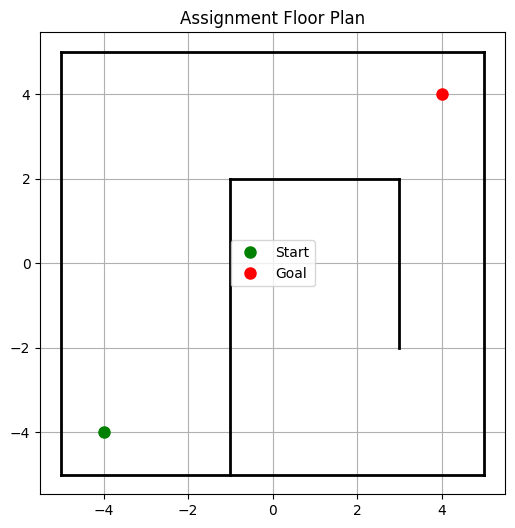

In [4]:
#@title Floor Plan Selection

floor_plan = "baseline" #@param ["baseline", "zigzag", "deadend", "symmetric"]


walls, start, goal = load_floor_plan(floor_plan)

plot_floor_plan(walls, start, goal)


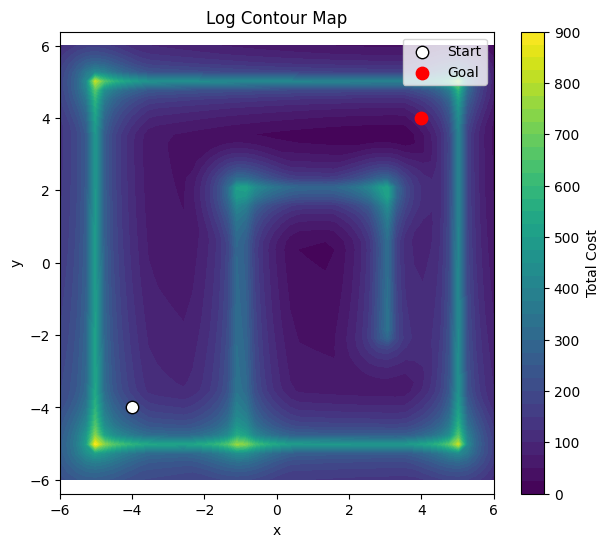

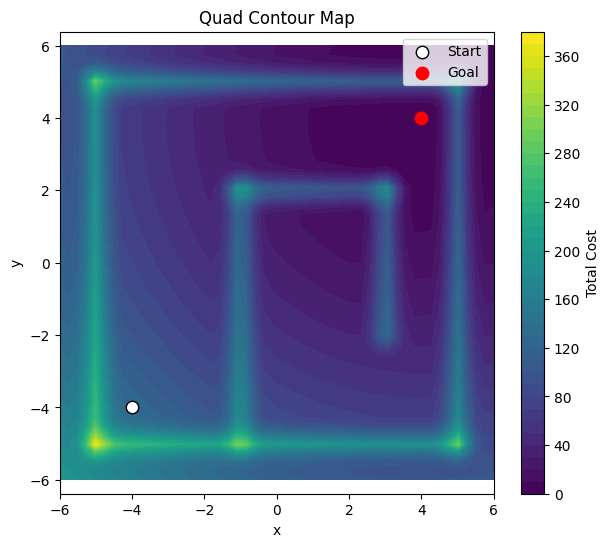

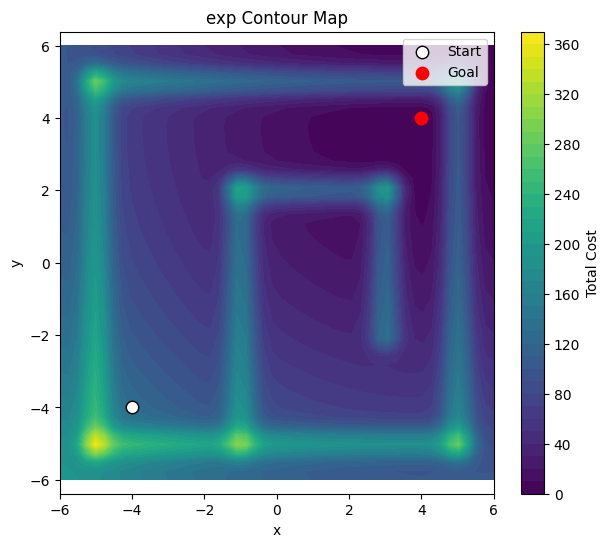

In [5]:
import matplotlib.pyplot as plt
import numpy as np



#bassically calculates the distance from the x to the goal the higher it is the worse it is
def goal_cost(x, goal):
    #the distance formula basically, halfing to make it not run at mach 10 towards the goal might change it
    return  np.sum((x - goal)**2)


# -------------------------------
# Wall penalty (quadratic band)
# -------------------------------
def wall_penalty(x, a, b, R):
    d = point_to_segment_distance(x, a, b)
    if d <= R:
        return 0.5 * (R - d)**2
    else:
        return 0.0


# -------------------------------
# Wall penalty (Student Made)
# -------------------------------
def wall_penalty_log(x, a, b, R):
    d = point_to_segment_distance(x, a, b)
    if d <= R:

        e = 0.01
        return np.log(R / (d + e))
    else:
        return 0.0
        

#4th
#starting s =0.5
#increasing s to 2
#made it more fuzzy, increasing not the way to go

#4rth, exp 2nd
#s = 0.3
#this one seems the best balance bewteen range and desnity

#it was a bug
#i forgot to change from the quad to exp in the code
#thats why it was almost unseeable

def wall_penalty_exp(x, a, b, R):
    d = point_to_segment_distance(x, a, b)
    
    if d <= R:

        s = 0.3
        return np.exp(- (d ** 2) / (2 * s ** 2))
    else:
        return 0.0



#x is the current pos, walls is walls, penelaty is the selected type, weights is how strong the repulsion is
# r is the max distance before it has no wieght
def wall_cost(x,walls,penalty,weight,r):
    total = 0.0

    #goes through all the walls
    for a, b in walls:

        if penalty == "quad":
            total += wall_penalty(x, a, b, r)
        elif penalty == "log":
            total += wall_penalty_log(x, a, b, r)
        elif penalty == "exp":
            total += wall_penalty_exp(x, a, b, r)

    return total * weight



def total_cost(x,goal,walls,penalty,weight,r):
    c_goal = goal_cost(x,goal)

    c_walls = wall_cost(x,walls,penalty,weight,r)

    return c_goal + c_walls




xmin, xmax = -6, 6
ymin, ymax = -6, 6
N = 50

xs = np.linspace(xmin, xmax, N)
ys = np.linspace(ymin, ymax, N)
X, Y = np.meshgrid(xs, ys)



# calculates the cost at all points to create the contour map log
Z = np.zeros_like(X)

for i in range(N):
    for j in range(N):
        x = np.array([X[j, i], Y[j, i]])
        Z[j, i] = total_cost(x,goal,walls,penalty="log", weight=100,r=1.5)



plt.figure(figsize=(7, 6))
contours = plt.contourf(X, Y, Z, levels=40, cmap="viridis")
plt.colorbar(contours, label="Total Cost")

plt.scatter(start[0], start[1], c="white", s=80, edgecolors="black", label="Start")
plt.scatter(goal[0], goal[1], c="red", s=80, label="Goal")

plt.title("Log Contour Map")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.legend()
plt.show()

    


# calculates the cost at all points to create the contour map, so we see weight at all points
Z = np.zeros_like(X)
#starting r = 1
#starting weight = 5
#walls are almost unseeable in all 

#2nd
# r= 2
# wieght = 20
#better visabiltiy on quad
#r seems to not be doing much at this point so leaving it at 2

#3rd
#r = 2
# weight = 40
# quad walls are now clearly visable but expnitonals are not



#4rd
#r = 0.75
# weight = 400
# lowerd r due to the fact that it made the dead end more or less the same value as the goal itself
# ive hit the wall with weight here quad
#  the best weight might be a bit higher but not by much

for i in range(N):
    for j in range(N):
        x = np.array([X[j, i], Y[j, i]])
        Z[j, i] = total_cost(x,goal,walls,penalty="quad", weight= 400.0,r=0.75)



plt.figure(figsize=(7, 6))
contours = plt.contourf(X, Y, Z, levels=40, cmap="viridis")
plt.colorbar(contours, label="Total Cost")

plt.scatter(start[0], start[1], c="white", s=80, edgecolors="black", label="Start")
plt.scatter(goal[0], goal[1], c="red", s=80, label="Goal")

plt.title("Quad Contour Map")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.legend()
plt.show()


# calculates the cost at all points to create the contour map
Z = np.zeros_like(X)

# made the r = 2 due to exponents having longer range

for i in range(N):
    for j in range(N):
        x = np.array([X[j, i], Y[j, i]])
        Z[j, i] = total_cost(x,goal,walls,penalty="exp", weight=100.0,r=2.0)



plt.figure(figsize=(7, 6))
contours = plt.contourf(X, Y, Z, levels=40, cmap="viridis")
plt.colorbar(contours, label="Total Cost")

plt.scatter(start[0], start[1], c="white", s=80, edgecolors="black", label="Start")
plt.scatter(goal[0], goal[1], c="red", s=80, label="Goal")

plt.title("exp Contour Map")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.legend()
plt.show()






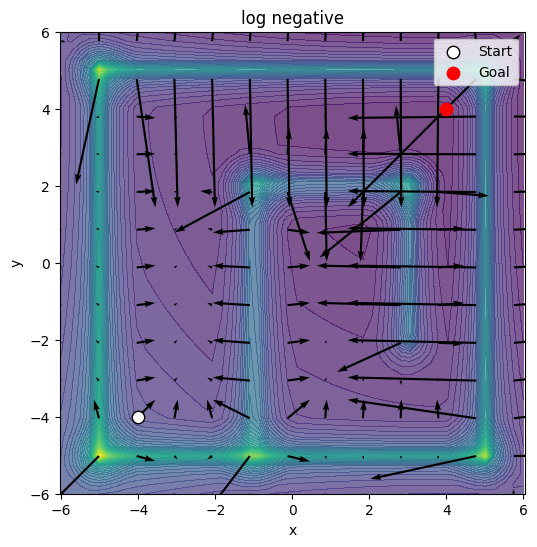

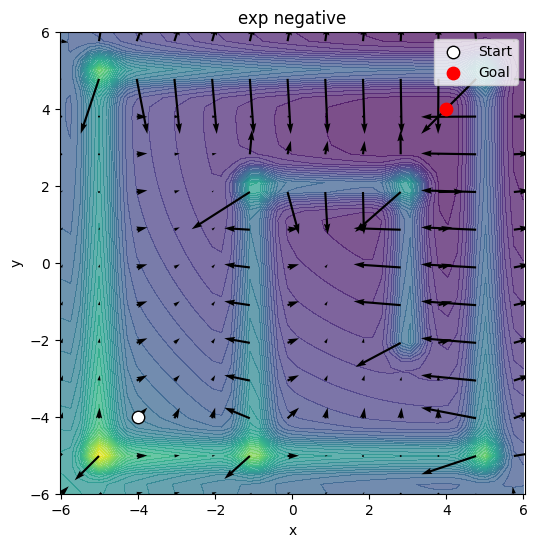

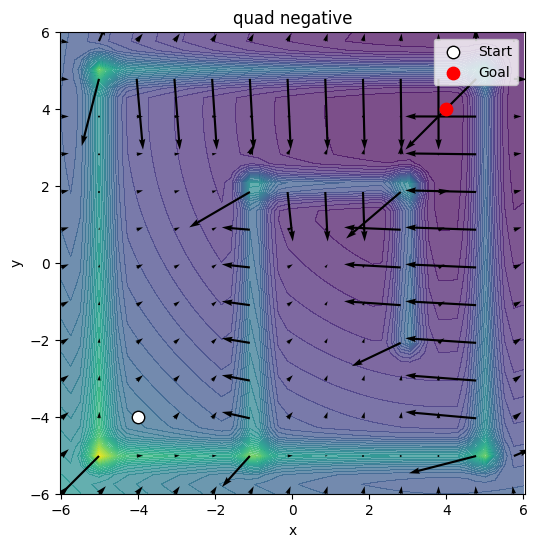

In [6]:

    
Z = np.zeros_like(X)

xmin, xmax = -6, 6
ymin, ymax = -6, 6
N = 50


#kinda copy pasted the code over from countour functions from the cell above but it works


#This method is pretty inefficent as technically it could all be done in one for loop
#however this is easier
for i in range(N):
    for j in range(N):
        x = np.array([X[j, i], Y[j, i]])
        Z[j, i] = total_cost(x,goal,walls,penalty="log", weight=100.0,r=1.0)


dZdy, dZdx = np.gradient(Z)

U = -dZdx
V = -dZdy


#visuals

plt.figure(figsize=(6, 6))

plt.contourf(X, Y, Z, levels=40, cmap="viridis", alpha=0.7)

step = 4

#increasing scale to showcase log function easier
plt.quiver(X[::step, ::step], Y[::step, ::step],
               U[::step, ::step], V[::step, ::step],
               color="black", scale=500)

plt.scatter(start[0], start[1], c="white", s=80, edgecolors="black", label="Start")
plt.scatter(goal[0], goal[1], c="red", s=80, label="Goal")

plt.title("log negative")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.legend()
plt.show()





for i in range(N):
    for j in range(N):
        x = np.array([X[j, i], Y[j, i]])
        Z[j, i] = total_cost(x,goal,walls,penalty="exp", weight=100.0,r=2.0)


dZdy, dZdx = np.gradient(Z)

U = -dZdx
V = -dZdy


#visuals

plt.figure(figsize=(6, 6))

plt.contourf(X, Y, Z, levels=40, cmap="viridis", alpha=0.7)

step = 4
plt.quiver(X[::step, ::step], Y[::step, ::step],
               U[::step, ::step], V[::step, ::step],
               color="black", scale=300)

plt.scatter(start[0], start[1], c="white", s=80, edgecolors="black", label="Start")
plt.scatter(goal[0], goal[1], c="red", s=80, label="Goal")

plt.title("exp negative")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.legend()
plt.show()




for i in range(N):
    for j in range(N):
        x = np.array([X[j, i], Y[j, i]])
        Z[j, i] = total_cost(x,goal,walls,penalty="quad", weight= 400.0,r=0.75)


dZdy, dZdx = np.gradient(Z)

U = -dZdx
V = -dZdy


#visuals

plt.figure(figsize=(6, 6))

plt.contourf(X, Y, Z, levels=40, cmap="viridis", alpha=0.7)

step = 4
plt.quiver(X[::step, ::step], Y[::step, ::step],
               U[::step, ::step], V[::step, ::step],
               color="black", scale=300)

plt.scatter(start[0], start[1], c="white", s=80, edgecolors="black", label="Start")
plt.scatter(goal[0], goal[1], c="red", s=80, label="Goal")

plt.title("quad negative")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.legend()
plt.show()


#Note even though Log has a signficantly higher scale you can still see how much weight being around the walls is
#also visable is the sharp increase not realy visable in another other graph









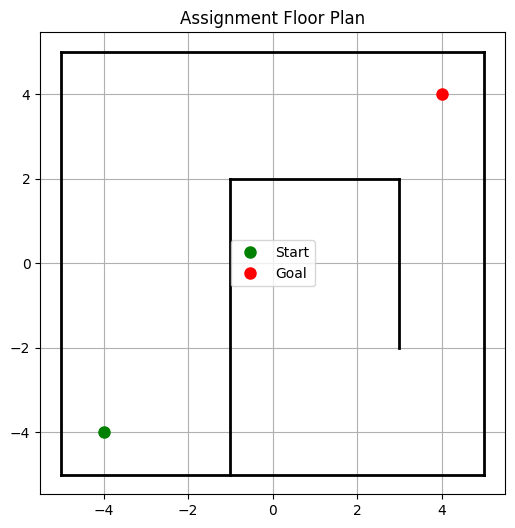

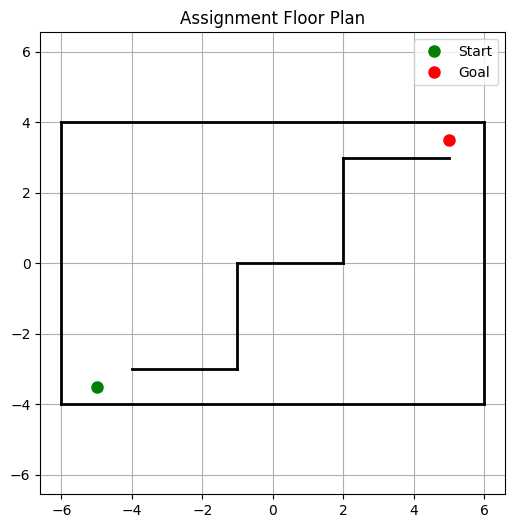

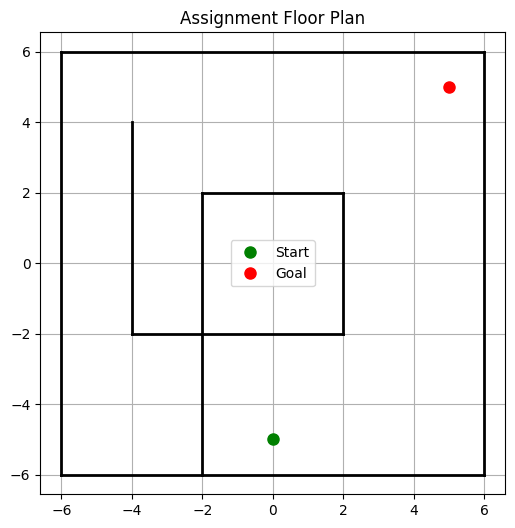

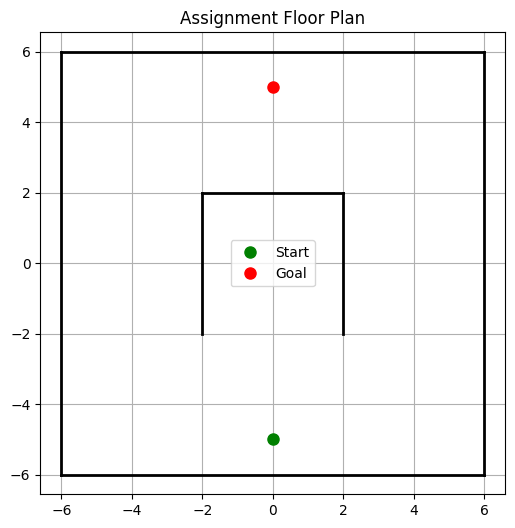

In [7]:
#bit confused on the last bullet point of 2.4, it states a plot showing walls, start, and goal positons
# but is the floor plan code not that already? 

floor_plan = "baseline" #@param ["baseline", "zigzag", "deadend", "symmetric"]


walls, start, goal = load_floor_plan(floor_plan)

plot_floor_plan(walls, start, goal)

floor_plan = "zigzag" #@param ["baseline", "zigzag", "deadend", "symmetric"]


walls, start, goal = load_floor_plan(floor_plan)

plot_floor_plan(walls, start, goal)\

floor_plan = "deadend" #@param ["baseline", "zigzag", "deadend", "symmetric"]


walls, start, goal = load_floor_plan(floor_plan)

plot_floor_plan(walls, start, goal)

floor_plan = "symmetric" #@param ["baseline", "zigzag", "deadend", "symmetric"]


walls, start, goal = load_floor_plan(floor_plan)

plot_floor_plan(walls, start, goal)




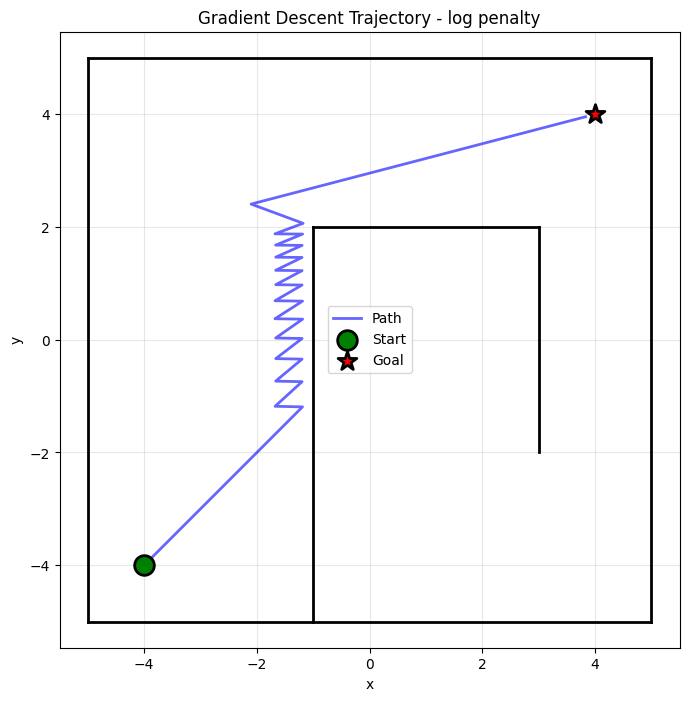

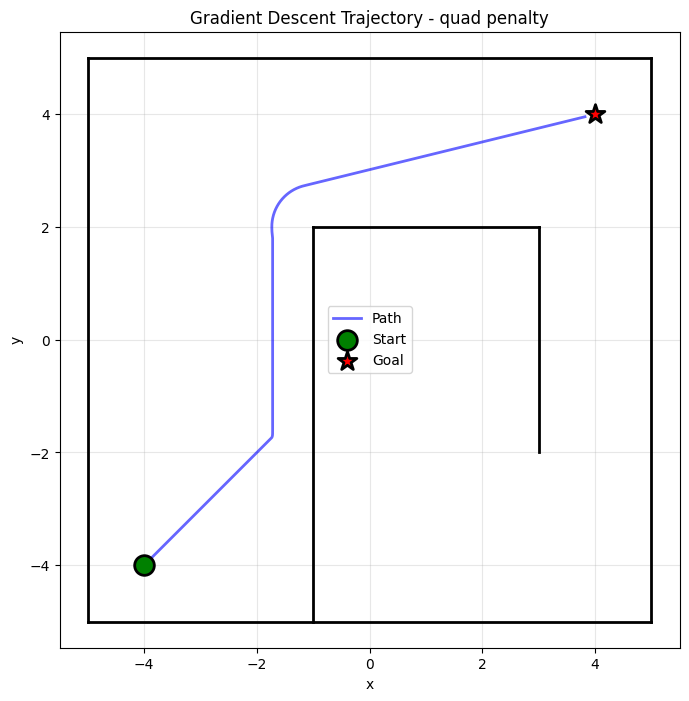

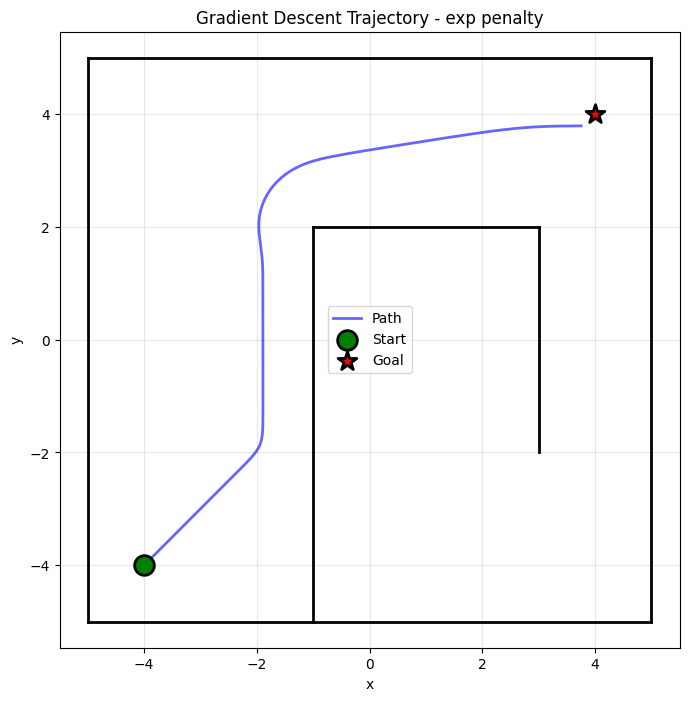

In [8]:
walls, start, goal = load_floor_plan("baseline")

#How far it moves every iterations

learning_rate = 0.001
max_iterations = 2500
tolerance = 0.1  #goal hitbox 

penalty = "log"

weight = 100.0
r = 0.2


trajectory = [start.copy()]
current_pos = start.copy()

for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


#quad

penalty = "quad"

weight = 400.0
r = 0.75


trajectory = [start.copy()]
current_pos = start.copy()

for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#exponitial

penalty = "exp"

weight = 100.0
r = 2


# Initialize trajectory
trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()





#Note log is the sharpest which makes sense
#quad is somewhat soft but there are momments of sharpnesss such as when first apporching the wall
#exp is by far the softest with a smooth curve overall




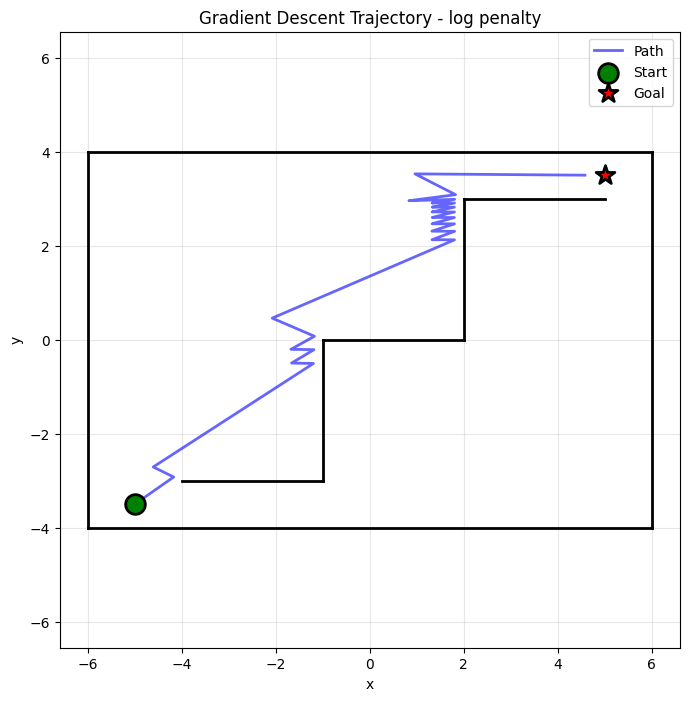

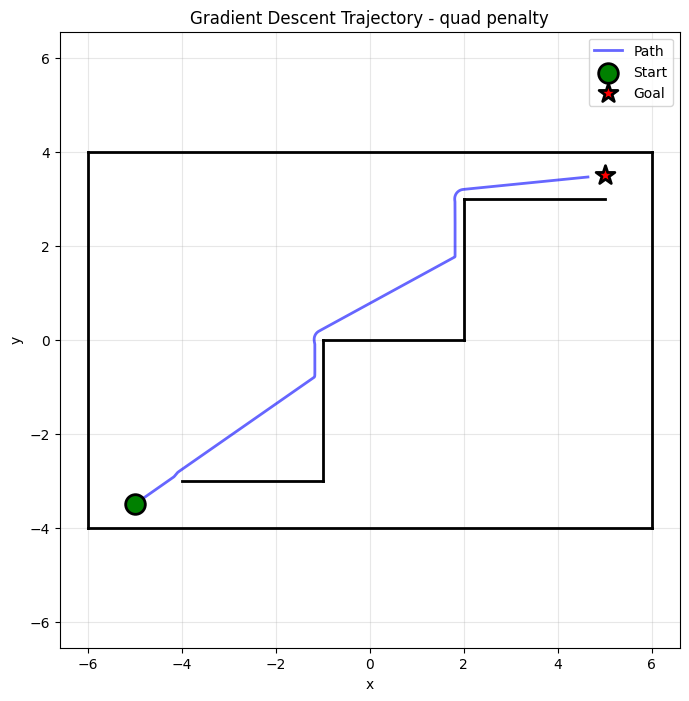

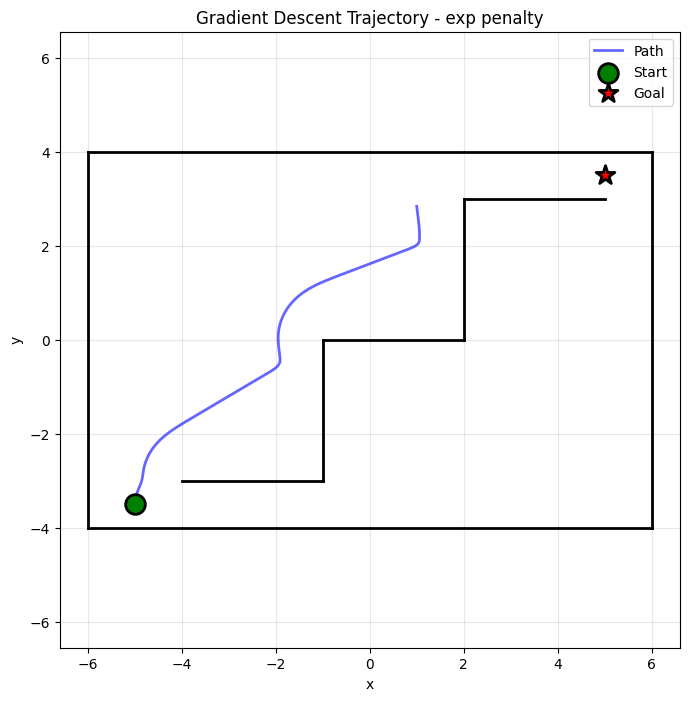

In [9]:
walls, start, goal = load_floor_plan("zigzag") #@param ["baseline", "zigzag", "deadend", "symmetric"]

#How far it moves every iterations

learning_rate = 0.001
max_iterations = 2500
tolerance = 0.1  #goal hitbox 

penalty = "log"

weight = 100.0
r = 0.2


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


#quad

penalty = "quad"

weight = 400.0
#with a modiefed range it can actually make it
#orginal r = 0.75
r = 0.2


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#exponitial

penalty = "exp"

weight = 100.0
r = 2


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()





#Note log is the only one that makes it due to its much smaller wall radiuis and sharpness
#quad and exp are too soft to make it. quad can make it with a lower r. exp cannot and instead bugs out with a lower r





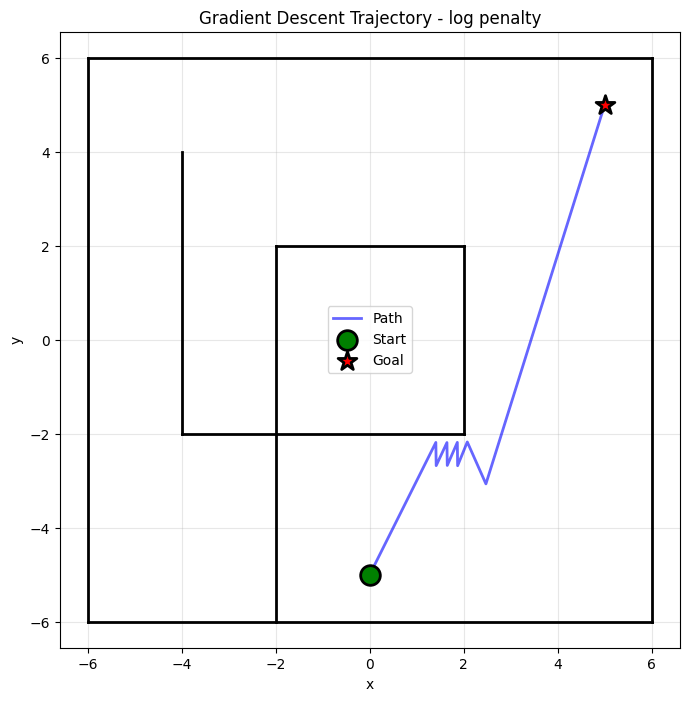

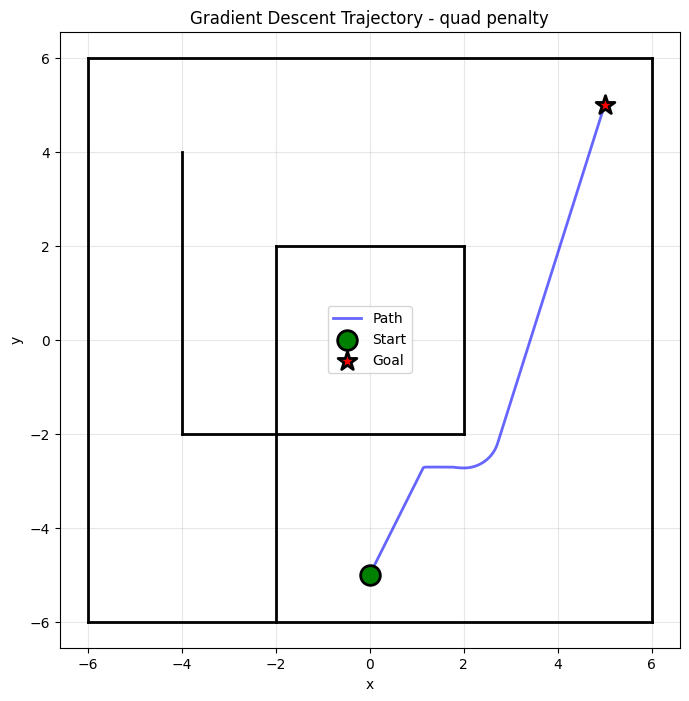

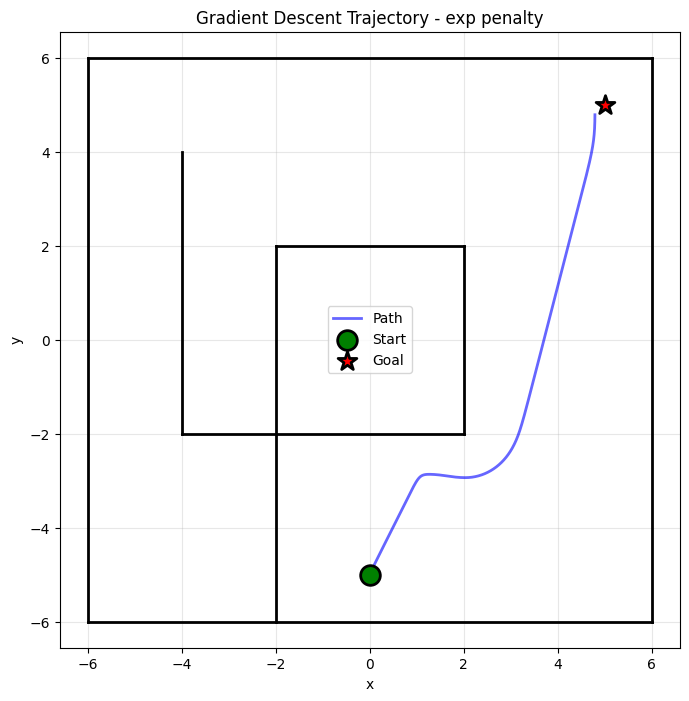

In [10]:
walls, start, goal = load_floor_plan("deadend") #@param ["baseline", "zigzag", "deadend", "symmetric"]

#How far it moves every iterations

learning_rate = 0.001
max_iterations = 2500
tolerance = 0.1  #goal hitbox 

penalty = "log"

weight = 100.0
r = 0.2


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


#quad

penalty = "quad"

weight = 400.0
r = 0.75


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#exponitial

penalty = "exp"

weight = 100.0
r = 2


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()





#Note all three make it but log as expected does a little boomerang bounce of the wall serveral times






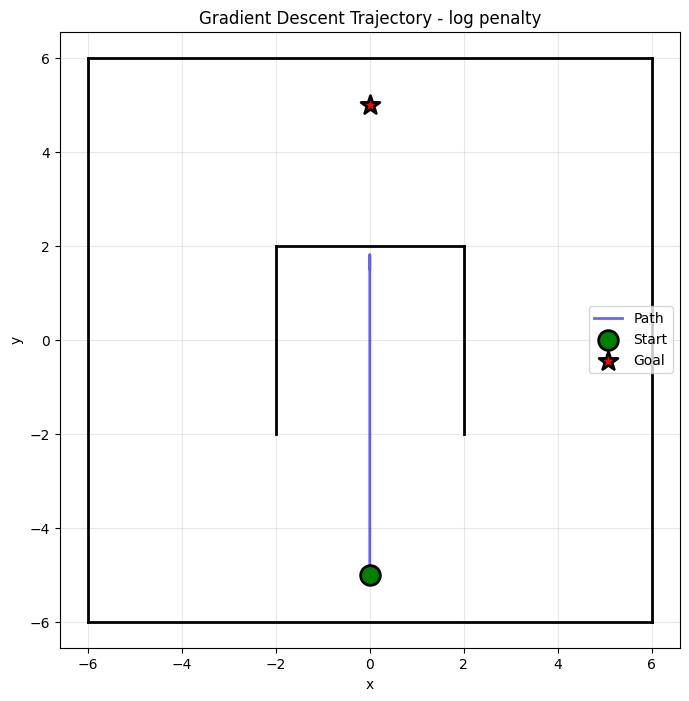

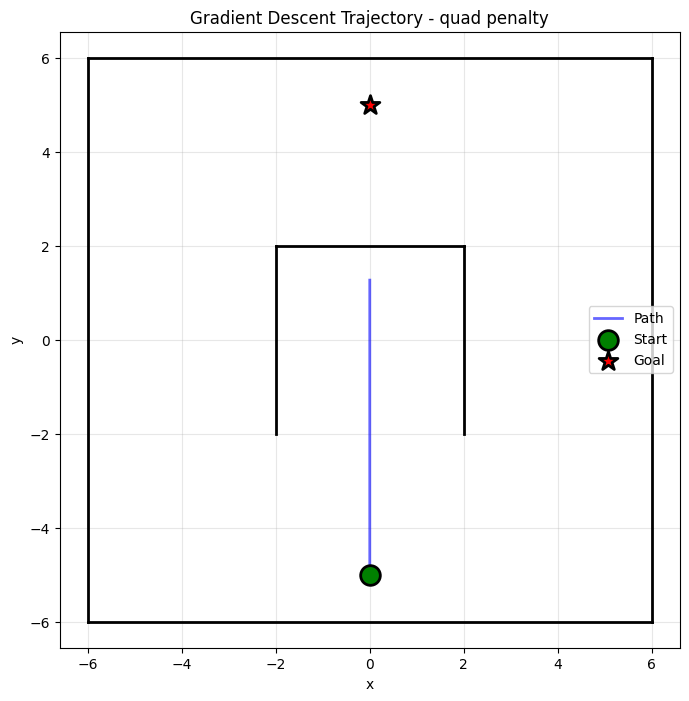

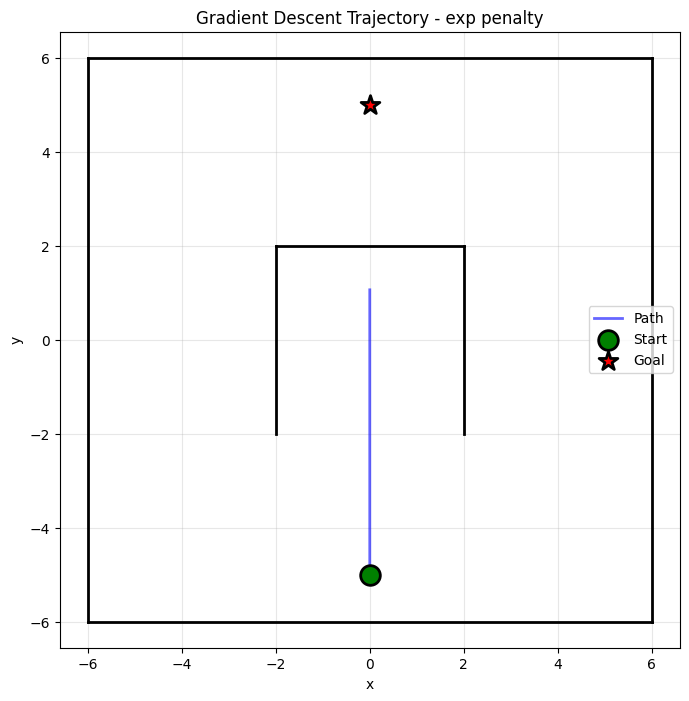

In [11]:
walls, start, goal = load_floor_plan("symmetric") #@param ["baseline", "zigzag", "deadend", "symmetric"]

#How far it moves every iterations

learning_rate = 0.001
max_iterations = 2500
tolerance = 0.1  #goal hitbox 

penalty = "log"

weight = 100.0
r = 0.2


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


#quad

penalty = "quad"

weight = 400.0
r = 0.75


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#exponitial

penalty = "exp"

weight = 100.0
r = 2


trajectory = [start.copy()]
current_pos = start.copy()

# Gradient descent loop
for iteration in range(max_iterations):


    #did we reach the star?
    distance_to_goal = np.linalg.norm(current_pos - goal)
    if distance_to_goal < tolerance:
        break
    
   
    epsilon = 1e-5
    grad = np.zeros(2)
    
    for i in range(2):
        x_plus = current_pos.copy()
        x_minus = current_pos.copy()
        x_plus[i] += epsilon
        x_minus[i] -= epsilon
        
        cost_plus = total_cost(x_plus, goal, walls, penalty, weight, r)
        cost_minus = total_cost(x_minus, goal, walls, penalty, weight, r)
        
        grad[i] = (cost_plus - cost_minus) / (2 * epsilon)
    
    current_pos = current_pos - learning_rate * grad
    
    trajectory.append(current_pos.copy())

trajectory = np.array(trajectory)



plt.figure(figsize=(8, 8))

for a, b in walls:
    plt.plot([a[0], b[0]], [a[1], b[1]], 'k-', linewidth=2)

plt.plot(trajectory[:, 0], trajectory[:, 1], 'b-', alpha=0.6, linewidth=2, label='Path')

#visuals
plt.scatter(start[0], start[1], c='green', s=200, marker='o', 
           edgecolors='black', linewidth=2, label='Start', zorder=5)
plt.scatter(goal[0], goal[1], c='red', s=200, marker='*', 
           edgecolors='black', linewidth=2, label='Goal', zorder=5)

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Gradient Descent Trajectory - {penalty} penalty')
plt.axis('equal')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()





#Note all three get stuck in the hole, it seems that they cannot handle pockets like this. log gets closest to the wall as expected






In [12]:
#2.6 questons

#R affects the path alot, with log it affects how close the point gets to the wall with an r too high causing it to fly off the map entierly
# with quad and exp it more or less affects the range of the walls influence with higher increasing the range of the walls influence but not nesscairly the strength

# in narrow corridors exp fails due to it being too soft and long range, Quad can fail but with a tighter r it can make it past. Log passes
# mostly due to its sharpness and its range being very low

#Yes, exp as mentioned before gets stuck in narrow corridors, and all 3 get stuck with the bucket in symatry. this is probably due to any lack of randomization in the movment
#resulting in it just bouncing up and down without being able to move either left or right to adjust and get out of the bucket.